## Multi-Seed Training & Evaluation: Fly Connectome PPO vs Shuffled Connectome PPO

This notebook trains **2 additional independent seeds** (`NEW_SEEDS = [101, 202]`) specifically for **`fly`** and **`fly_shuffled`**, saves their connectome/policy checkpoints, and evaluates them alongside the existing **5M-step `seed = 42`** models (`fly_ppo.pt` / `fly_shuffled_ppo.pt`) across **50 traffic seeds (`1000..1049`)**.

### What Each Seed Controls & Saves
- **Existing baseline seed (`BASE_SEED = 42`, already trained ~5M steps):**
  - `artifacts/checkpoints/fly_ppo.pt` (identical to `artifacts/checkpoints_archive/fly_ppo_new_env.pt`)
  - `artifacts/checkpoints/fly_shuffled_ppo.pt` + `artifacts/fly_subconnectome_shuffled.pt`
- **For each new seed `s` in `NEW_SEEDS` (`101`, `202`):**
  1. Generates & saves an independent random-rewired null-model graph: `artifacts/fly_subconnectome_shuffled_seed{s}.pt`.
  2. Trains & saves `Fly Connectome PPO` (`seed = s`): `artifacts/checkpoints/fly_ppo_seed{s}.pt`.
  3. Trains & saves `Shuffled Connectome PPO` (`seed = s`): `artifacts/checkpoints/fly_shuffled_ppo_seed{s}.pt`.

> **Note on Training Time:** `total_timesteps` is set to **`5_000_000` (5M steps)** per model (`4` new models total). Checkpoints auto-save every 250 updates (~256k steps) and on interrupt, so `RESUME = True` can continue from where you stopped.

In [1]:
%load_ext autoreload
%autoreload 2
from concurrent.futures import ProcessPoolExecutor, as_completed
from dataclasses import asdict, dataclass
from datetime import datetime
import json
import multiprocessing as mp
import os
from pathlib import Path
import sys

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import torch

from fly_traffic.config import (
    BenchmarkConfig,
    ConnectomeConfig,
    DEFAULT_ARTIFACTS_DIR,
    DEFAULT_DATASET_PATH,
    PROJECT_ROOT,
)
for extra_path in (str(PROJECT_ROOT / "src"), str(PROJECT_ROOT / "scripts")):
    if extra_path not in sys.path:
        sys.path.insert(0, extra_path)

existing_py_path = os.environ.get("PYTHONPATH", "")
py_parts = [p for p in existing_py_path.split(os.pathsep) if p]
for extra_path in (str(PROJECT_ROOT / "src"), str(PROJECT_ROOT / "scripts")):
    if extra_path not in py_parts:
        py_parts.insert(0, extra_path)
os.environ["PYTHONPATH"] = os.pathsep.join(py_parts)

from fly_traffic.connectome.artifact import ConnectomeArtifact
from fly_traffic.connectome.shuffled import (
    default_shuffled_connectome_path,
    load_or_create_shuffled_connectome,
)
from fly_traffic.training.ppo_trainer import PPOTrainer
from train_agents import copy_checkpoints, print_parameter_table, train_agent_worker

## 1. Configurations

### 1.1 PPO Configurations

Default `total_timesteps` is set to **5,000,000** to match the full `new_env` training budget.

In [2]:
@dataclass(frozen=True)
class PPOConfig:
    """Hyperparameters for recurrent PPO training (5M-step full budget)."""
    total_timesteps: int = 5_000_000
    num_envs: int = 8
    rollout_steps: int = 128
    sequence_chunk_len: int = 16
    num_minibatches: int = 4
    update_epochs: int = 4
    learning_rate: float = 8e-4
    gamma: float = 0.99
    gae_lambda: float = 0.95
    clip_coef: float = 0.2
    ent_coef: float = 0.005
    vf_coef: float = 0.25
    max_grad_norm: float = 0.5
    anneal_lr: bool = True
    seed: int = 42
    num_cpu_threads: int = 4
    checkpoints_dir: Path = DEFAULT_ARTIFACTS_DIR / "checkpoints"

### 1.2 Traffic Environment Configurations

In [3]:
@dataclass(frozen=True)
class TrafficEnvConfig:
    """Configuration for the 4-way, 2-lane Gymnasium traffic environment (Env v2)."""
    dt_seconds: float = 2.0
    max_steps: int = 500
    max_lane_capacity: int = 30
    queue_obs_norm_capacity: float = 30.0
    hard_max_lane_capacity: int = 80
    straight_discharge_rate: float = 2.5
    turn_discharge_rate: float = 2.0
    min_green_steps: int = 6
    yellow_steps: int = 2
    all_red_steps: int = 1
    wait_penalty_alpha: float = 0.1
    switch_penalty_beta: float = 1.0
    reward_scale: float = 0.005
    max_wait_norm_seconds: float = 150.0
    max_elapsed_norm_steps: float = 20.0
    profile_name: str = "mixed"
    collision_penalty: float = 80.0
    red_light_wait_threshold_s: float = 150.0
    red_light_max_prob: float = 0.14
    dilemma_zone_prob: float = 0.18
    enable_collisions: bool = True

### 1.3 Multi-Seed Run Configuration & Shuffled Graph Verification

- `NEW_SEEDS = [101, 202]`: the 2 new training + graph-rewiring seeds.
- `PARALLEL_MODELS`: set `1` for sequential loop (live step-by-step logs in notebook), or `2..4` to train `(agent, seed)` jobs concurrently across CPU worker processes.

In [4]:
AGENTS = ["fly", "fly_shuffled"]

BASE_SEED = 42             # Already trained (~5M steps in fly_ppo.pt & fly_shuffled_ppo.pt)
NEW_SEEDS = [101, 202]     # 2 additional seeds to train & save
ALL_SEEDS = [BASE_SEED, *NEW_SEEDS]

TOTAL_TIMESTEPS = PPOConfig.total_timesteps
NUM_ENVS = PPOConfig.num_envs
LR = PPOConfig.learning_rate

CONNECTOME_PATH = Path(ConnectomeConfig.output_path)
CHECKPOINTS_DIR = Path(PPOConfig.checkpoints_dir)
ARCHIVE_DIR = DEFAULT_ARTIFACTS_DIR / "checkpoints_archive"

RESUME = True        # Resume from existing {agent}_ppo_seed{seed}.pt when available
PARALLEL_MODELS = 1  # 1 = sequential (live logs) | 2..4 = parallel worker processes

conn_config = ConnectomeConfig(output_path=CONNECTOME_PATH)
if not conn_config.output_path.exists():
    raise FileNotFoundError(
        f"Sub-connectome artifact not found at {conn_config.output_path}. "
        "Run scripts/extract_connectome.py first."
    )

bio_artifact = ConnectomeArtifact.load(conn_config.output_path)
print_parameter_table(AGENTS, bio_artifact)

# Pre-generate / load shuffled connectomes for all seeds and verify distinct wiring
shuffled_artifacts_by_seed = {}
print("\n=== Shuffled Null-Model Connectomes by Seed ===")
for s in ALL_SEEDS:
    shuf_path = default_shuffled_connectome_path(conn_config.output_path, seed=s)
    shuf_art = load_or_create_shuffled_connectome(
        connectome_path=conn_config.output_path,
        shuffled_path=shuf_path,
        seed=s,
    )
    shuffled_artifacts_by_seed[s] = (shuf_path, shuf_art)
    meta = shuf_art.metadata
    print(
        f"  seed={s:<4d} | file={shuf_path.name:<38s} | "
        f"exc={meta.exc_edge_count} inh={meta.inh_edge_count} | "
        f"cross_region={meta.cross_region_edges} | rho={meta.scaled_spectral_radius:.4f}"
    )

def _edge_set(art: ConnectomeArtifact) -> set[tuple[int, int]]:
    idx = art.w_exc_indices.numpy()
    return set(zip(idx[0].tolist(), idx[1].tolist()))

edge_sets = {s: _edge_set(shuffled_artifacts_by_seed[s][1]) for s in ALL_SEEDS}
print("\nPairwise excitatory edge overlap across shuffled seeds (random expectation ~0.59%):")
for i, s1 in enumerate(ALL_SEEDS):
    for s2 in ALL_SEEDS[i + 1:]:
        overlap_pct = 100.0 * len(edge_sets[s1] & edge_sets[s2]) / max(1, len(edge_sets[s1]))
        print(f"  seed {s1} vs seed {s2}: {overlap_pct:.2f}% shared edges")

=== Policy Parameter Comparison (obs_dim=22, act_dim=4) ===
  FLY  | trainable=  70006 | total_params=  70006 | hidden_dim=2500
  FLY_SHUFFLED | trainable=  70006 | total_params=  70006 | hidden_dim=2500

=== Shuffled Null-Model Connectomes by Seed ===
  seed=42   | file=fly_subconnectome_shuffled.pt          | exc=36908 inh=50263 | cross_region=35430 | rho=0.9500
  seed=101  | file=fly_subconnectome_shuffled_seed101.pt  | exc=36908 inh=50263 | cross_region=35230 | rho=0.9500
  seed=202  | file=fly_subconnectome_shuffled_seed202.pt  | exc=36908 inh=50263 | cross_region=35097 | rho=0.9500


/home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/src/fly_traffic/connectome/artifact.py:122: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  return w_exc_coo.to_sparse_csr(), w_inh_coo.to_sparse_csr()



Pairwise excitatory edge overlap across shuffled seeds (random expectation ~0.59%):
  seed 42 vs seed 101: 0.59% shared edges
  seed 42 vs seed 202: 0.63% shared edges
  seed 101 vs seed 202: 0.65% shared edges


## 2. Backup Existing Seed Checkpoints

Back up any existing `{agent}_ppo_seed{s}.pt` files in `artifacts/checkpoints/` to `artifacts/checkpoints/backups/` before training.

In [5]:
backup_dir = CHECKPOINTS_DIR / "backups"
backup_dir.mkdir(parents=True, exist_ok=True)
ts = datetime.now().strftime("%Y%m%d_%H%M%S")

for s in NEW_SEEDS:
    copy_checkpoints(
        agents=AGENTS,
        checkpoints_dir=CHECKPOINTS_DIR,
        suffix=f"_seed{s}",
        backup_dir=backup_dir,
        timestamp=ts,
    )

Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/fly_ppo_seed101.pt
Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/fly_shuffled_ppo_seed101.pt
Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/fly_ppo_seed202.pt
Skipping missing checkpoint: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/checkpoints/fly_shuffled_ppo_seed202.pt


## 3. Train `Fly` & `Shuffled` on the 2 New Seeds (`101`, `202`)

Single unified training cell: runs **sequentially** when `PARALLEL_MODELS == 1` or **in parallel** across `ProcessPoolExecutor` workers when `PARALLEL_MODELS >= 2`. Saves checkpoints to:
- `artifacts/checkpoints/fly_ppo_seed101.pt` & `artifacts/checkpoints/fly_shuffled_ppo_seed101.pt`
- `artifacts/checkpoints/fly_ppo_seed202.pt` & `artifacts/checkpoints/fly_shuffled_ppo_seed202.pt`

In [7]:
if PARALLEL_MODELS < 2:
    for s in NEW_SEEDS:
        suffix = f"_seed{s}"
        shuf_path, shuf_art = shuffled_artifacts_by_seed[s]

        trainer = PPOTrainer(
            ppo_config=PPOConfig(
                total_timesteps=TOTAL_TIMESTEPS,
                num_envs=NUM_ENVS,
                seed=s,
                checkpoints_dir=CHECKPOINTS_DIR,
                learning_rate=LR,
            ),
            env_config=TrafficEnvConfig(),
            connectome_config=conn_config,
        )

        for model_type in AGENTS:
            model_artifact = bio_artifact if model_type == "fly" else shuf_art
            filename = f"{model_type}_ppo{suffix}.pt"
            ckpt = CHECKPOINTS_DIR / filename
            resume_from = ckpt if (RESUME and ckpt.exists()) else None

            print(
                f"\n--- {model_type.upper()} PPO | seed={s} | resume={resume_from is not None} | "
                f"{TOTAL_TIMESTEPS} steps | lr={LR} ---",
                flush=True,
            )
            trainer.train(
                model_type=model_type,
                artifact=model_artifact,
                verbose=True,
                checkpoint_filename=filename,
                resume_from=resume_from,
                learning_rate=LR,
                shuffled_connectome_path=shuf_path if model_type == "fly_shuffled" else None,
            )
else:
    jobs = [(model_type, s) for s in NEW_SEEDS for model_type in AGENTS]
    max_workers = min(PARALLEL_MODELS, len(jobs))
    ppo_overrides = asdict(PPOConfig())
    env_overrides = asdict(TrafficEnvConfig())

    print(f"Launching {len(jobs)} parallel training jobs (max_workers={max_workers}): {jobs}", flush=True)
    with ProcessPoolExecutor(
        max_workers=max_workers, mp_context=mp.get_context("spawn")
    ) as executor:
        futures = {
            executor.submit(
                train_agent_worker,
                model_type,
                TOTAL_TIMESTEPS,
                NUM_ENVS,
                s,
                CONNECTOME_PATH,
                CHECKPOINTS_DIR,
                f"_seed{s}",
                RESUME,
                LR,
                ppo_overrides,
                env_overrides,
            ): (model_type, s)
            for model_type, s in jobs
        }
        for future in as_completed(futures):
            model_type, s = futures[future]
            future.result()  # raise immediately if any worker fails
            print(f"[MAIN] {model_type.upper()} (seed={s}) finished and saved.", flush=True)


--- FLY PPO | seed=101 | resume=True | 5000000 steps | lr=0.0008 ---
[FLY] update=1425/4882 steps=1459200 sps= 752.6 rew=-13.252 tp=   0.0 rew_iqm=-13.252 pg_loss=-0.0099 v_loss= 0.4766 ent=0.270
[FLY] update=1430/4882 steps=1464320 sps= 394.3 rew=-63.175 tp= 635.4 rew_iqm=-52.079 pg_loss=-0.0165 v_loss= 0.4591 ent=0.309
[FLY] update=1440/4882 steps=1474560 sps= 405.5 rew=-57.918 tp= 603.8 rew_iqm=-49.145 pg_loss=-0.0069 v_loss= 3.4074 ent=0.288
[FLY] update=1450/4882 steps=1484800 sps= 412.2 rew=-64.579 tp= 662.3 rew_iqm=-55.819 pg_loss=-0.0116 v_loss= 0.2406 ent=0.285
[FLY] update=1460/4882 steps=1495040 sps= 415.7 rew=-58.883 tp= 612.5 rew_iqm=-50.972 pg_loss=-0.0019 v_loss= 3.0186 ent=0.281
[FLY] update=1470/4882 steps=1505280 sps= 417.3 rew=-60.467 tp= 631.7 rew_iqm=-53.379 pg_loss=-0.0115 v_loss= 0.2333 ent=0.321
[FLY] update=1480/4882 steps=1515520 sps= 418.6 rew=-59.107 tp= 599.3 rew_iqm=-49.237 pg_loss=-0.0026 v_loss= 1.1884 ent=0.264
[FLY] update=1490/4882 steps=1525760 sps=

### 3.1 Inspect & Verify All 6 Seed Checkpoints (`Seed 42`, `Seed 101`, `Seed 202`)

In [8]:
def resolve_seed_checkpoint(model_type: str, seed: int) -> Path:
    """Locate checkpoint path for base seed (42) or newly trained seeds."""
    if seed == BASE_SEED:
        primary = CHECKPOINTS_DIR / f"{model_type}_ppo.pt"
        archive = ARCHIVE_DIR / f"{model_type}_ppo_new_env.pt"
        if primary.exists():
            p_meta = torch.load(primary, map_location="cpu", weights_only=True)
            if int(p_meta.get("trained_timesteps", 0)) >= 4_000_000:
                return primary
        if archive.exists():
            return archive
        return primary
    return CHECKPOINTS_DIR / f"{model_type}_ppo_seed{seed}.pt"

print("=== Checkpoint Inventory Across All Seeds ===")
for s in ALL_SEEDS:
    for model_type in AGENTS:
        ckpt_path = resolve_seed_checkpoint(model_type, s)
        if not ckpt_path.exists():
            print(f"  [MISSING] seed={s:<4d} | {model_type:<13s} | expected at {ckpt_path}")
            continue
        meta = torch.load(ckpt_path, map_location="cpu", weights_only=True)
        steps = int(meta.get("trained_timesteps", 0))
        tau = meta.get("leak_rate_tau")
        size_mb = ckpt_path.stat().st_size / (1024 * 1024)
        print(
            f"  [READY]   seed={s:<4d} | {model_type:<13s} | steps={steps:<8d} | "
            f"tau={tau:.4f} | {size_mb:.2f} MB | {ckpt_path.name}"
        )

=== Checkpoint Inventory Across All Seeds ===
  [READY]   seed=42   | fly           | steps=5000192  | tau=0.5390 | 1.27 MB | fly_ppo.pt
  [READY]   seed=42   | fly_shuffled  | steps=4999168  | tau=0.5002 | 1.27 MB | fly_shuffled_ppo.pt
  [READY]   seed=101  | fly           | steps=4999168  | tau=0.6222 | 1.27 MB | fly_ppo_seed101.pt
  [READY]   seed=101  | fly_shuffled  | steps=4999168  | tau=0.4768 | 1.27 MB | fly_shuffled_ppo_seed101.pt
  [READY]   seed=202  | fly           | steps=4999168  | tau=0.5951 | 1.27 MB | fly_ppo_seed202.pt
  [READY]   seed=202  | fly_shuffled  | steps=4999168  | tau=0.5329 | 1.27 MB | fly_shuffled_ppo_seed202.pt


## 4. Multi-Seed Benchmark & Topology Isolation Analysis

Requires all 3 seeds (`42`, `101`, `202`) to be trained first (`REQUIRE_ALL_SEEDS = True`) so cross-seed `Mean +/- Std` is computed over `N = 3` seeds.

In [9]:
from fly_traffic.agents.base import NeuralAgentAdapter
from fly_traffic.agents.baselines import load_policy_checkpoint
from fly_traffic.agents.fixed_timer import FixedTimerAgent
from fly_traffic.environment.traffic_env import TrafficIntersectionEnv
from fly_traffic.evaluation.evaluator import AgentEvaluator
from fly_traffic.evaluation.visualizer import BenchmarkPlotter

MULTISEED_OUTPUT_DIR = Path(BenchmarkConfig.output_dir) / "multiseed_fly_vs_shuffled"
EVAL_SEEDS = tuple(range(1000, 1050))  # 50 deterministic traffic arrival seeds
REQUIRE_ALL_SEEDS = True               # Prevent accidental N=1 evaluation before Section 3 finishes

BENCHMARK_LABELS = {
    "fly": "Fly Connectome PPO",
    "fly_shuffled": "Shuffled Connectome PPO",
}

missing_ckpts = [
    resolve_seed_checkpoint(model_type, s)
    for s in ALL_SEEDS
    for model_type in AGENTS
    if not resolve_seed_checkpoint(model_type, s).exists()
]
if REQUIRE_ALL_SEEDS and missing_ckpts:
    missing_str = "\n  - ".join(str(p) for p in missing_ckpts)
    raise FileNotFoundError(
        "Cannot run N=3 multi-seed evaluation yet because the new seed checkpoints "
        f"have not been trained/saved (run Section 3 first):\n  - {missing_str}"
    )

eval_agents = []
loaded_agents_by_seed: dict[int, dict[str, NeuralAgentAdapter]] = {}
histories: dict[str, dict[str, list[float]]] = {}

for s in ALL_SEEDS:
    shuf_path, shuf_art = shuffled_artifacts_by_seed[s]
    loaded_agents_by_seed[s] = {}
    for model_type in AGENTS:
        ckpt_path = resolve_seed_checkpoint(model_type, s)
        if not ckpt_path.exists():
            print(f"Skipping missing checkpoint: {ckpt_path}")
            continue
        policy, payload = load_policy_checkpoint(
            path=ckpt_path,
            artifact=bio_artifact if model_type == "fly" else None,
            shuffled_artifact=shuf_art if model_type == "fly_shuffled" else None,
        )
        display_name = f"{BENCHMARK_LABELS[model_type]} (seed {s})"
        adapter = NeuralAgentAdapter(policy=policy, agent_name=display_name)
        eval_agents.append(adapter)
        loaded_agents_by_seed[s][model_type] = adapter
        if isinstance(payload.get("history"), dict):
            histories[display_name] = payload["history"]

eval_agents.append(FixedTimerAgent())
print(f"Loaded {len(eval_agents)} controllers across {len(ALL_SEEDS)} seeds for 50-seed evaluation.")

Loaded 7 controllers across 3 seeds for 50-seed evaluation.


In [10]:
bench_cfg = BenchmarkConfig(
    eval_seeds=EVAL_SEEDS,
    output_dir=MULTISEED_OUTPUT_DIR,
)
evaluator = AgentEvaluator(
    benchmark_config=bench_cfg,
    env_config=TrafficEnvConfig(),
)

scenario_results = evaluator.evaluate_all_agents(eval_agents)

# Paired per-episode collision & reward analysis on stress_test for each training/rewiring seed
paired_stress_stats = {}
for s, pair in loaded_agents_by_seed.items():
    if "fly" not in pair or "fly_shuffled" not in pair:
        continue
    fly_cols, shuf_cols = [], []
    fly_rews, shuf_rews = [], []
    for ep_seed in EVAL_SEEDS:
        for agent_key, col_list, rew_list in [
            ("fly", fly_cols, fly_rews),
            ("fly_shuffled", shuf_cols, shuf_rews),
        ]:
            env = TrafficIntersectionEnv(TrafficEnvConfig(profile_name="stress_test"))
            obs, _ = env.reset(seed=ep_seed)
            agent = pair[agent_key]
            agent.reset()
            done = False
            ep_rew = 0.0
            info = {}
            while not done:
                act = agent.select_action(obs, deterministic=True)
                obs, r, term, trunc, info = env.step(act)
                ep_rew += float(r)
                done = bool(term or trunc)
            col_list.append(int(info.get("total_collisions", 0)))
            rew_list.append(ep_rew)
            env.close()

    fly_arr = np.asarray(fly_cols)
    shuf_arr = np.asarray(shuf_cols)
    paired_stress_stats[s] = {
        "seed": s,
        "num_eval_episodes": len(EVAL_SEEDS),
        "fly_mean_collisions": float(fly_arr.mean()),
        "fly_std_collisions": float(fly_arr.std()),
        "fly_median_collisions": float(np.median(fly_arr)),
        "shuf_mean_collisions": float(shuf_arr.mean()),
        "shuf_std_collisions": float(shuf_arr.std()),
        "shuf_median_collisions": float(np.median(shuf_arr)),
        "fly_fewer_collisions_count": int(np.sum(fly_arr < shuf_arr)),
        "tie_collisions_count": int(np.sum(fly_arr == shuf_arr)),
        "fly_more_collisions_count": int(np.sum(fly_arr > shuf_arr)),
        "fly_mean_reward": float(np.mean(fly_rews)),
        "shuf_mean_reward": float(np.mean(shuf_rews)),
    }
print("Completed scenario evaluation and paired stress_test analysis.")

Completed scenario evaluation and paired stress_test analysis.


Saved multi-seed JSON: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/benchmarks/multiseed_fly_vs_shuffled/multiseed_summary.json
Saved multi-seed Markdown: /home/data/kuliah/rka/ML/reinforcement_learning/lalat lalu lintas/artifacts/benchmarks/multiseed_fly_vs_shuffled/multiseed_table.md



# Multi-Seed Fly vs Shuffled Evaluation Summary

## 1. Aggregated Performance Across Training / Rewiring Seeds

| Scenario | Architecture | Seeds (N) | Mean Reward (Across Seeds) | Mean Wait (s) | Mean Throughput | Mean Collisions (Across Seeds) |
|---|---|---:|---:|---:|---:|---:|
| normal | Fly Connectome PPO | 3 | -35.553 +/- 0.233 | 25.87 +/- 0.31 | 352.7 | 0.00 +/- 0.00 |
| normal | Shuffled Connectome PPO | 3 | -35.559 +/- 0.135 | 26.15 +/- 0.26 | 352.6 | 0.00 +/- 0.00 |
| asymmetric | Fly Connectome PPO | 3 | -48.880 +/- 0.224 | 23.11 +/- 0.41 | 572.8 | 0.00 +/- 0.00 |
| asymmetric | Shuffled Connectome PPO | 3 | -48.100 +/- 0.204 | 23.68 +/- 0.17 | 571.5 | 0.00 +/- 0.00 |
| rush_hour | Fly Connectome PPO | 3 | -78.960 +/- 0.456 | 27.59 +/- 0.31 | 881.4 | 0.01 +/- 0.01 |
| rush_hour | Shuffled Connectome PPO | 3 | -79.342 +/- 0.242 | 28.03 +/- 0.15 | 880.8 | 0.00 +/- 0.00 |
| stress_test | Fly Connectome PPO | 3 | -404.670 +/- 3.812 | 88.56 +/- 0.18 | 1460.1 | 7.05 +/- 1.94 |
| stress_test | Shuffled Connectome PPO | 3 | -401.897 +/- 6.130 | 87.60 +/- 1.28 | 1459.1 | 8.51 +/- 3.25 |

## 2. Paired `stress_test` Collision Isolation by Seed (50 Traffic Seeds Each)

| Training / Rewiring Seed | Fly Collisions (Mean +/- Std, Median) | Shuffled Collisions (Mean +/- Std, Median) | Fly < Shuffled (Win / Tie / Loss) | Fly Reward | Shuffled Reward |
|---:|---:|---:|---:|---:|---:|
| 42 | 4.34 +/- 2.77 (med 4.0) | 12.88 +/- 5.23 (med 13.0) | 46/50 (92%) [46W / 1T / 3L] | -399.310 | -402.899 |
| 101 | 8.02 +/- 3.79 (med 8.0) | 5.10 +/- 2.59 (med 5.0) | 8/50 (16%) [8W / 3T / 39L] | -407.856 | -393.939 |
| 202 | 8.80 +/- 4.23 (med 8.0) | 7.56 +/- 3.20 (med 7.0) | 21/50 (42%) [21W / 1T / 28L] | -406.843 | -408.854 |

## 3. Per-Controller Scenario Breakdown

# Benchmark Evaluation Results

## Scenario Comparison

| Scenario | Agent | Mean Reward | Mean Queue | Mean Wait (s) | Mean Throughput | Mean Switches | Mean Collisions | Inference (ms/step) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| normal | Fly Connectome PPO (seed 42) | -35.875 +/- 1.600 | 9.50 | 26.31 +/- 1.05 | 352.5 +/- 17.1 | 54.4 | 0.00 | 0.294 |
| normal | Shuffled Connectome PPO (seed 42) | -35.748 +/- 2.186 | 9.42 | 26.03 +/- 1.25 | 353.0 +/- 19.8 | 55.0 | 0.00 | 0.293 |
| normal | Fly Connectome PPO (seed 101) | -35.455 +/- 2.065 | 9.24 | 25.64 +/- 0.97 | 351.0 +/- 19.5 | 54.1 | 0.00 | 0.300 |
| normal | Shuffled Connectome PPO (seed 101) | -35.447 +/- 2.151 | 9.57 | 26.51 +/- 1.11 | 352.2 +/- 20.1 | 55.0 | 0.00 | 0.289 |
| normal | Fly Connectome PPO (seed 202) | -35.330 +/- 1.750 | 9.32 | 25.66 +/- 1.05 | 354.6 +/- 18.6 | 54.6 | 0.00 | 0.303 |
| normal | Shuffled Connectome PPO (seed 202) | -35.482 +/- 2.015 | 9.37 | 25.92 +/- 1.14 | 352.5 +/- 17.9 | 55.0 | 0.00 | 0.295 |
| normal | Fixed Timer | -41.354 +/- 2.308 | 11.25 | 31.25 +/- 1.28 | 349.2 +/- 20.0 | 45.0 | 0.00 | 0.002 |
| asymmetric | Fly Connectome PPO (seed 42) | -48.896 +/- 2.647 | 13.84 | 23.67 +/- 0.89 | 572.4 +/- 26.9 | 55.0 | 0.00 | 0.349 |
| asymmetric | Shuffled Connectome PPO (seed 42) | -47.840 +/- 2.606 | 13.89 | 23.76 +/- 0.87 | 572.2 +/- 25.9 | 55.0 | 0.00 | 0.350 |
| asymmetric | Fly Connectome PPO (seed 101) | -48.599 +/- 2.806 | 13.26 | 22.70 +/- 0.92 | 570.7 +/- 23.1 | 54.2 | 0.00 | 0.336 |
| asymmetric | Shuffled Connectome PPO (seed 101) | -48.124 +/- 2.959 | 13.91 | 23.83 +/- 0.86 | 570.6 +/- 26.5 | 54.9 | 0.00 | 0.522 |
| asymmetric | Fly Connectome PPO (seed 202) | -49.147 +/- 2.855 | 13.49 | 22.96 +/- 0.94 | 575.3 +/- 25.4 | 54.7 | 0.00 | 0.398 |
| asymmetric | Shuffled Connectome PPO (seed 202) | -48.337 +/- 2.714 | 13.72 | 23.44 +/- 0.92 | 571.8 +/- 27.3 | 55.0 | 0.00 | 0.372 |
| asymmetric | Fixed Timer | -61.765 +/- 3.094 | 19.23 | 33.04 +/- 1.00 | 570.2 +/- 25.0 | 45.0 | 0.00 | 0.002 |
| rush_hour | Fly Connectome PPO (seed 42) | -79.584 +/- 3.666 | 25.64 | 28.00 +/- 0.99 | 883.9 +/- 25.8 | 54.6 | 0.00 | 0.289 |
| rush_hour | Shuffled Connectome PPO (seed 42) | -79.682 +/- 3.475 | 25.65 | 28.08 +/- 0.92 | 882.2 +/- 28.8 | 54.3 | 0.00 | 0.279 |
| rush_hour | Fly Connectome PPO (seed 101) | -78.785 +/- 3.772 | 24.91 | 27.27 +/- 0.99 | 882.1 +/- 29.9 | 54.7 | 0.02 | 0.293 |
| rush_hour | Shuffled Connectome PPO (seed 101) | -79.198 +/- 3.366 | 25.64 | 28.17 +/- 0.84 | 877.9 +/- 30.0 | 54.2 | 0.00 | 0.283 |
| rush_hour | Fly Connectome PPO (seed 202) | -78.510 +/- 3.562 | 24.99 | 27.49 +/- 0.98 | 878.1 +/- 25.3 | 54.7 | 0.00 | 0.294 |
| rush_hour | Shuffled Connectome PPO (seed 202) | -79.145 +/- 4.354 | 25.43 | 27.82 +/- 1.20 | 882.2 +/- 26.0 | 54.7 | 0.00 | 0.275 |
| rush_hour | Fixed Timer | -104.975 +/- 6.900 | 35.55 | 38.86 +/- 1.95 | 856.2 +/- 24.6 | 45.0 | 0.00 | 0.002 |
| stress_test | Fly Connectome PPO (seed 42) | -399.310 +/- 22.310 | 145.34 | 88.43 +/- 4.80 | 1452.1 +/- 14.5 | 55.0 | 4.34 | 0.295 |
| stress_test | Shuffled Connectome PPO (seed 42) | -402.899 +/- 21.260 | 143.22 | 86.22 +/- 3.76 | 1465.1 +/- 12.8 | 55.0 | 12.88 | 0.285 |
| stress_test | Fly Connectome PPO (seed 101) | -407.856 +/- 19.531 | 147.31 | 88.81 +/- 3.72 | 1465.4 +/- 11.9 | 55.0 | 8.02 | 0.275 |
| stress_test | Shuffled Connectome PPO (seed 101) | -393.939 +/- 22.540 | 142.87 | 87.27 +/- 5.06 | 1451.5 +/- 11.2 | 54.8 | 5.10 | 0.360 |
| stress_test | Fly Connectome PPO (seed 202) | -406.843 +/- 21.247 | 146.72 | 88.44 +/- 4.19 | 1462.6 +/- 13.1 | 55.0 | 8.80 | 0.419 |
| stress_test | Shuffled Connectome PPO (seed 202) | -408.854 +/- 20.700 | 147.84 | 89.30 +/- 4.29 | 1460.5 +/- 12.6 | 55.0 | 7.56 | 0.414 |
| stress_test | Fixed Timer | -365.494 +/- 14.610 | 126.59 | 76.51 +/- 2.58 | 1487.1 +/- 31.6 | 45.0 | 19.62 | 0.002 |


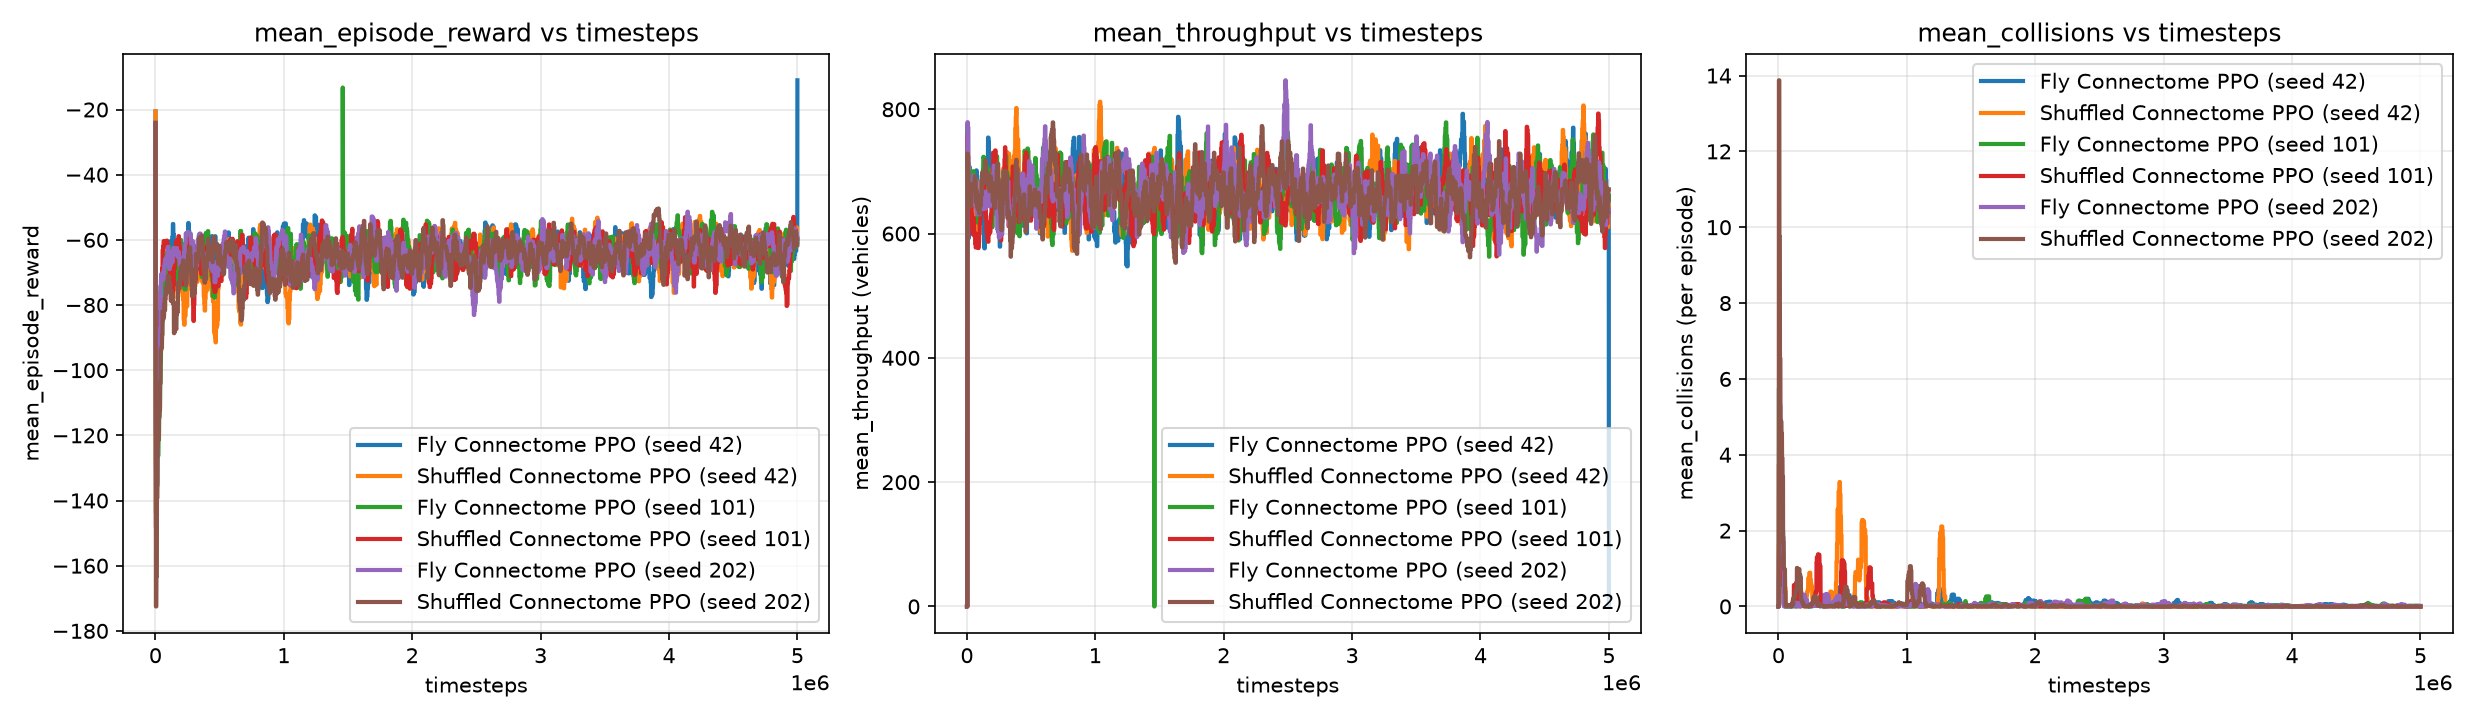

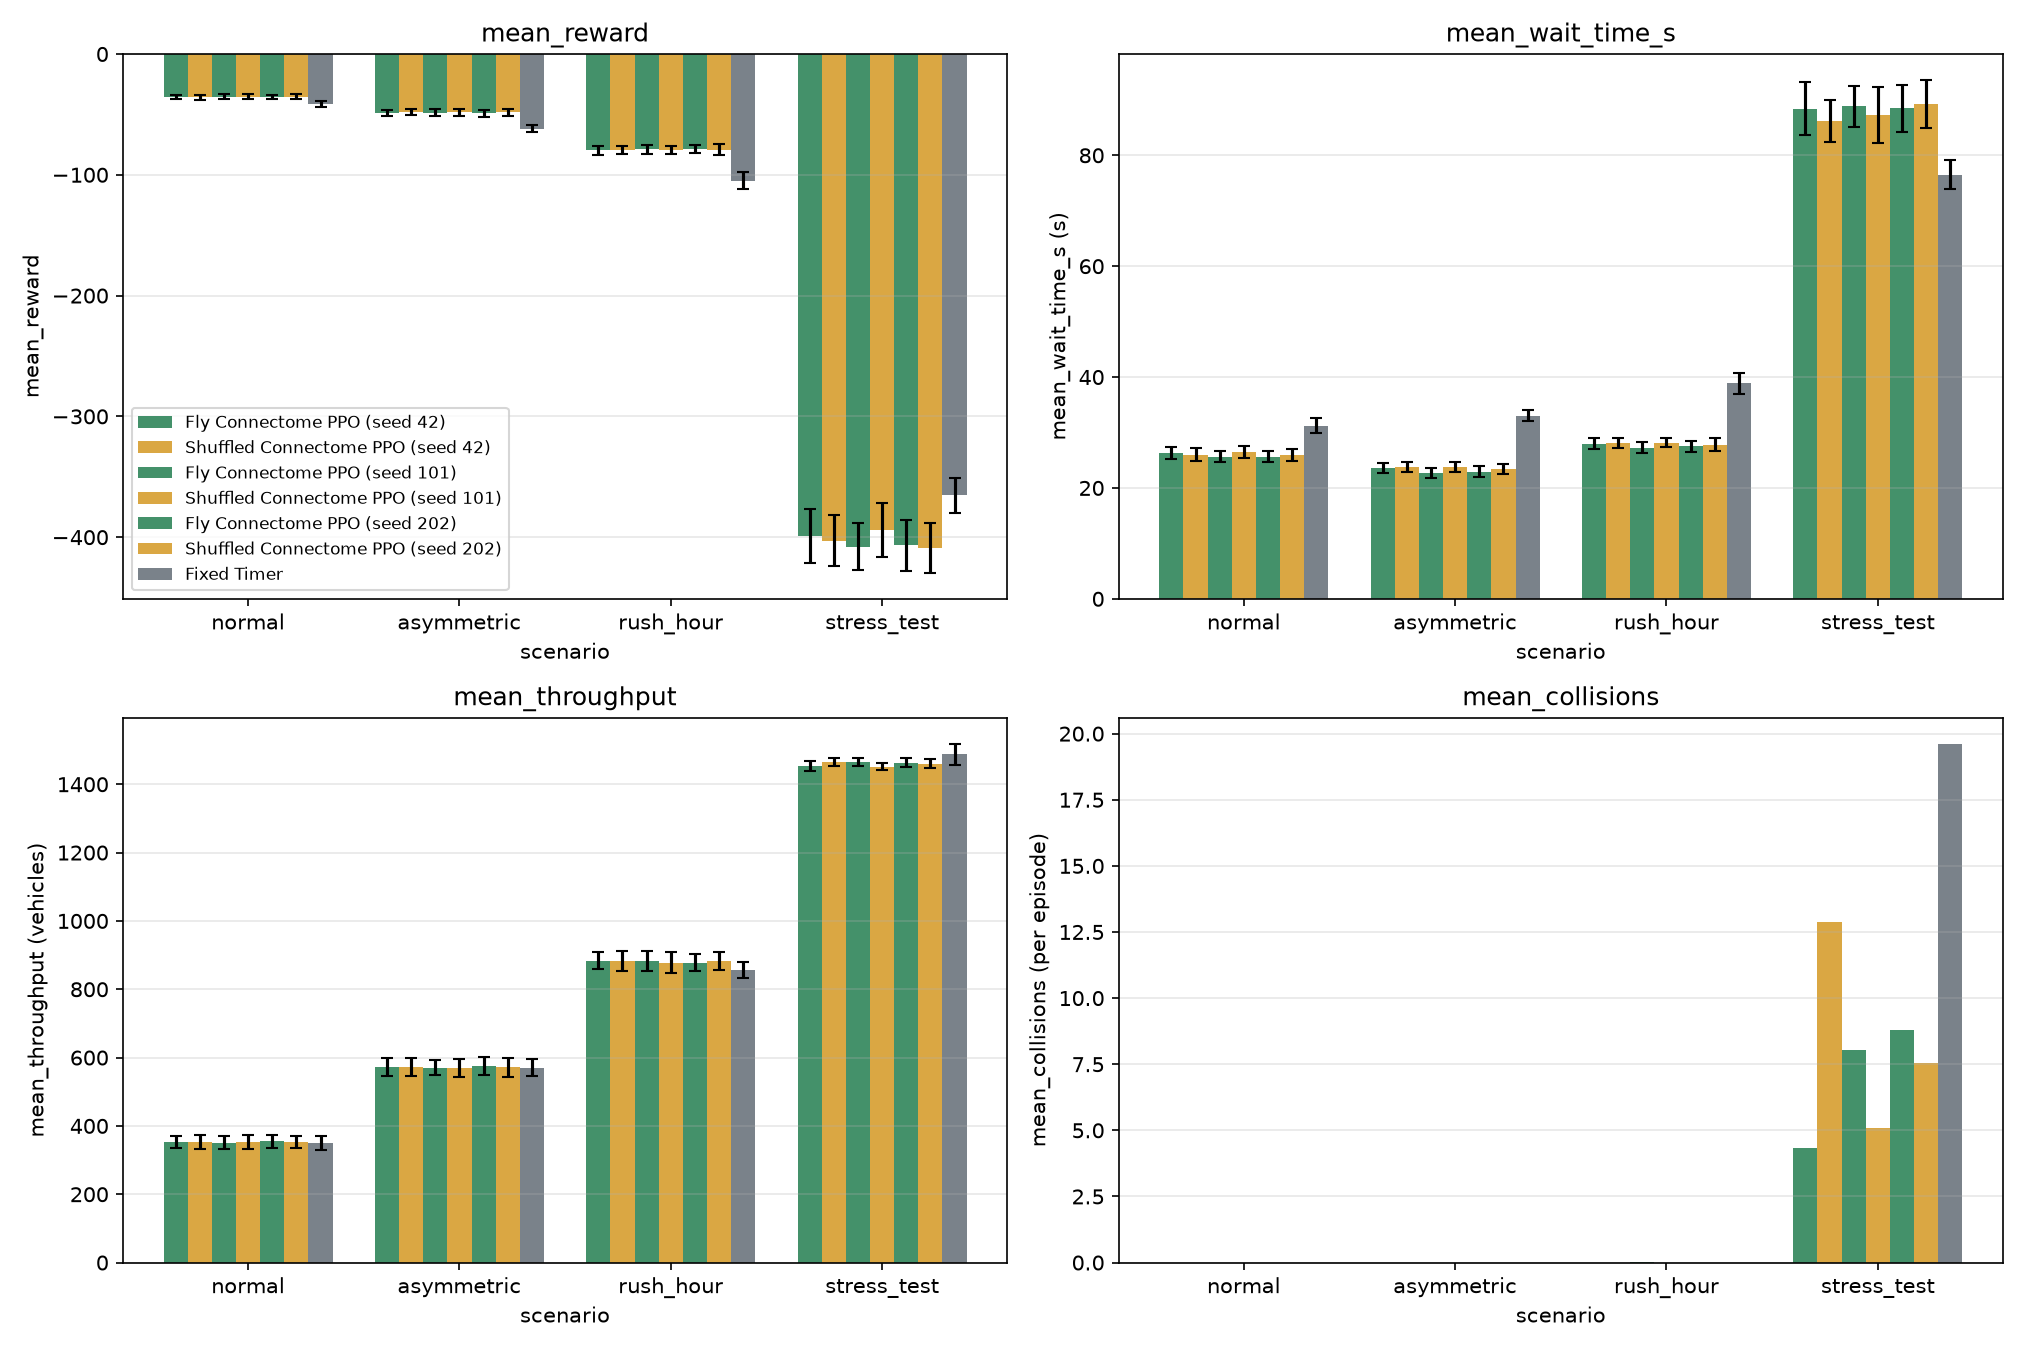

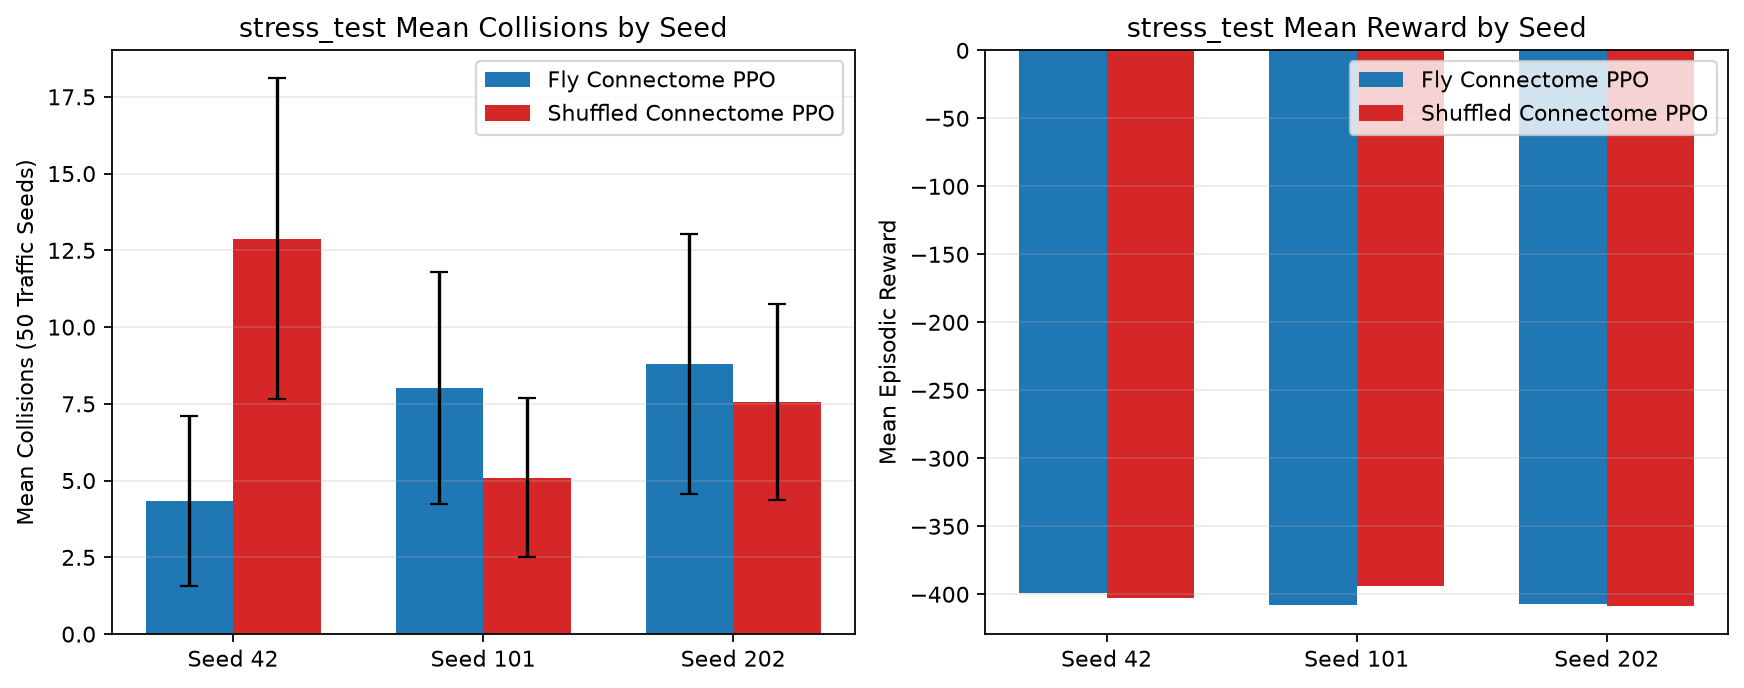

In [11]:
MULTISEED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save standard per-controller reports
json_path, md_path = evaluator.save_reports(
    output_dir=MULTISEED_OUTPUT_DIR,
    scenario_results=scenario_results,
    pharmacology_results=[],
)

# Aggregate cross-seed Mean +/- Std across training/rewiring seeds (N = len(available seeds))
cross_seed_summary = []
for scenario in bench_cfg.scenarios:
    for model_type, label in BENCHMARK_LABELS.items():
        matching = [
            r for r in scenario_results
            if r.scenario == scenario and r.agent_name.startswith(f"{label} (seed ")
        ]
        if not matching:
            continue
        cross_seed_summary.append({
            "scenario": scenario,
            "architecture": label,
            "num_model_seeds": len(matching),
            "eval_episodes_per_seed": matching[0].num_episodes,
            "mean_reward_across_seeds": float(np.mean([m.mean_reward for m in matching])),
            "std_reward_across_seeds": float(np.std([m.mean_reward for m in matching])),
            "mean_wait_s_across_seeds": float(np.mean([m.mean_wait_time_s for m in matching])),
            "std_wait_s_across_seeds": float(np.std([m.mean_wait_time_s for m in matching])),
            "mean_throughput_across_seeds": float(np.mean([m.mean_throughput for m in matching])),
            "mean_collisions_across_seeds": float(np.mean([m.mean_collisions for m in matching])),
            "std_collisions_across_seeds": float(np.std([m.mean_collisions for m in matching])),
        })

agg_lines = [
    "# Multi-Seed Fly vs Shuffled Evaluation Summary\n",
    "## 1. Aggregated Performance Across Training / Rewiring Seeds\n",
    "| Scenario | Architecture | Seeds (N) | Mean Reward (Across Seeds) | Mean Wait (s) | Mean Throughput | Mean Collisions (Across Seeds) |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for row in cross_seed_summary:
    agg_lines.append(
        f"| {row['scenario']} | {row['architecture']} | {row['num_model_seeds']} | "
        f"{row['mean_reward_across_seeds']:.3f} +/- {row['std_reward_across_seeds']:.3f} | "
        f"{row['mean_wait_s_across_seeds']:.2f} +/- {row['std_wait_s_across_seeds']:.2f} | "
        f"{row['mean_throughput_across_seeds']:.1f} | "
        f"{row['mean_collisions_across_seeds']:.2f} +/- {row['std_collisions_across_seeds']:.2f} |"
    )

if paired_stress_stats:
    agg_lines.extend([
        "\n## 2. Paired `stress_test` Collision Isolation by Seed (50 Traffic Seeds Each)\n",
        "| Training / Rewiring Seed | Fly Collisions (Mean +/- Std, Median) | Shuffled Collisions (Mean +/- Std, Median) | Fly < Shuffled (Win / Tie / Loss) | Fly Reward | Shuffled Reward |",
        "|---:|---:|---:|---:|---:|---:|",
    ])
    for s, st in paired_stress_stats.items():
        win_pct = 100.0 * st["fly_fewer_collisions_count"] / max(1, st["num_eval_episodes"])
        agg_lines.append(
            f"| {s} | {st['fly_mean_collisions']:.2f} +/- {st['fly_std_collisions']:.2f} (med {st['fly_median_collisions']:.1f}) | "
            f"{st['shuf_mean_collisions']:.2f} +/- {st['shuf_std_collisions']:.2f} (med {st['shuf_median_collisions']:.1f}) | "
            f"{st['fly_fewer_collisions_count']}/{st['num_eval_episodes']} ({win_pct:.0f}%) "
            f"[{st['fly_fewer_collisions_count']}W / {st['tie_collisions_count']}T / {st['fly_more_collisions_count']}L] | "
            f"{st['fly_mean_reward']:.3f} | {st['shuf_mean_reward']:.3f} |"
        )

agg_lines.append("\n## 3. Per-Controller Scenario Breakdown\n")
agg_lines.append(md_path.read_text(encoding="utf-8"))

multiseed_md_path = MULTISEED_OUTPUT_DIR / "multiseed_table.md"
multiseed_md_path.write_text("\n".join(agg_lines), encoding="utf-8")

multiseed_json_path = MULTISEED_OUTPUT_DIR / "multiseed_summary.json"
multiseed_json_path.write_text(
    json.dumps(
        {
            "eval_seeds": list(EVAL_SEEDS),
            "model_seeds": ALL_SEEDS,
            "cross_seed_summary": cross_seed_summary,
            "paired_stress_test_by_seed": paired_stress_stats,
        },
        indent=2,
    ),
    encoding="utf-8",
)

plot_paths = []
if histories:
    p_curves = MULTISEED_OUTPUT_DIR / "training_curves_multiseed.png"
    BenchmarkPlotter.plot_training_curves(histories=histories, output_path=p_curves)
    plot_paths.append(p_curves)

p_scenarios = MULTISEED_OUTPUT_DIR / "scenario_comparison_multiseed.png"
BenchmarkPlotter.plot_scenario_comparison(results=scenario_results, output_path=p_scenarios)
plot_paths.append(p_scenarios)

if paired_stress_stats:
    seeds_done = list(paired_stress_stats.keys())
    x = np.arange(len(seeds_done))
    width = 0.35
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), dpi=160)

    fly_c = [paired_stress_stats[s]["fly_mean_collisions"] for s in seeds_done]
    fly_ce = [paired_stress_stats[s]["fly_std_collisions"] for s in seeds_done]
    shuf_c = [paired_stress_stats[s]["shuf_mean_collisions"] for s in seeds_done]
    shuf_ce = [paired_stress_stats[s]["shuf_std_collisions"] for s in seeds_done]

    axes[0].bar(x - width / 2, fly_c, width, yerr=fly_ce, capsize=4, label="Fly Connectome PPO", color="#1f77b4")
    axes[0].bar(x + width / 2, shuf_c, width, yerr=shuf_ce, capsize=4, label="Shuffled Connectome PPO", color="#d62728")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels([f"Seed {s}" for s in seeds_done])
    axes[0].set_ylabel("Mean Collisions (50 Traffic Seeds)")
    axes[0].set_title("stress_test Mean Collisions by Seed")
    axes[0].grid(axis="y", alpha=0.25)
    axes[0].legend()

    fly_r = [paired_stress_stats[s]["fly_mean_reward"] for s in seeds_done]
    shuf_r = [paired_stress_stats[s]["shuf_mean_reward"] for s in seeds_done]
    axes[1].bar(x - width / 2, fly_r, width, label="Fly Connectome PPO", color="#1f77b4")
    axes[1].bar(x + width / 2, shuf_r, width, label="Shuffled Connectome PPO", color="#d62728")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels([f"Seed {s}" for s in seeds_done])
    axes[1].set_ylabel("Mean Episodic Reward")
    axes[1].set_title("stress_test Mean Reward by Seed")
    axes[1].grid(axis="y", alpha=0.25)
    axes[1].legend()

    fig.tight_layout()
    p_consistency = MULTISEED_OUTPUT_DIR / "stress_test_seed_consistency.png"
    fig.savefig(p_consistency, bbox_inches="tight")
    plt.close(fig)
    plot_paths.append(p_consistency)

print(f"Saved multi-seed JSON: {multiseed_json_path}")
print(f"Saved multi-seed Markdown: {multiseed_md_path}\n")
display(Markdown(multiseed_md_path.read_text(encoding="utf-8")))
for fig_path in plot_paths:
    display(Image(filename=str(fig_path)))